# Policy Ranking Agreement — Coat re-ranking (Q3, MNAR reference)

Reads compact provenance from `outputs/in_distribution/policy_ranking_agreement_rerank/`.

**Question**: does a user simulator rank recommender policies in the same order as *unbiased* held-out data?

**Why Coat.** Every other instance of this experiment ranks policies against exposure-biased held-out
labels, so "the simulator agrees with the benchmark" cannot separate *being right* from *reproducing the
benchmark's bias*. Coat's 290 workers rated 24 self-selected coats (MNAR) **and** 16 assigned uniformly at
random (MCAR). The MCAR half is an unbiased reference ordering, which is what makes the comparison
interpretable here.

**Protocol (`policy_reranking`)**, differing from the ml-1m/Steam `policy_ranking` protocol in two ways:

| | ml-1m / Steam | Coat |
|---|---|---|
| candidate construction | free retrieval from the full catalog | each policy **re-ranks the user's own 16-item MCAR pool** and emits its top-k |
| k | 10 | **5** |
| labels on the slate | zero-filled where the user never interacted | **every slot carries a real label** — no zero-fill |
| reference | exposure-biased held-out split | **unbiased (MCAR)** |
| seeds | 10 | **1** — see below |
| eval users | 1000 sampled | **all 290** |

**One seed is not an oversight.** On ml-1m the seed drives the 80/20 split and the 1000-user sample, both
of which move the reference. On Coat the reference is the entire MCAR half and every user is evaluated, and
`load_policy_roster(policy_seed=0)` is never overridden by any runner — so additional seeds would be
byte-identical runs. Every seed-averaging idiom from the ml-1m notebook is therefore replaced here by a
**method** axis: the spread that matters is across scorers, not across seeds.

**Main metric**: `test.kendall_tau` (scipy tau-b, so ties are handled). Spearman's ρ is secondary.

**Sections**
1. Setup and artifact collection
2. Run inventory and roster parity
3. The reference ordering — and how stable it is
4. Per-run results
5. τ leaderboard against the popularity floor
6. How much of that is signal? (user-level bootstrap)
7. Per-policy utilities
8. Where the rankings diverge
9. Scorer-family cuts
10. Call volume and dedup
11. Verifications
12. Coverage matrix

In [3]:
from __future__ import annotations

import json
import re
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)


def find_repo_root(start: Path | None = None) -> Path:
    path = (start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "pyproject.toml").exists() and candidate.name == "beyond-click-sim":
            return candidate
    raise RuntimeError("Could not find beyond-click-sim repo root")


REPO_ROOT = find_repo_root()
RESULTS_ROOT = REPO_ROOT / "outputs" / "in_distribution" / "policy_ranking_agreement_rerank"

DATASET_LABELS = {"coat": "Coat", "ml-1m": "ML-1M", "steam": "Steam"}

# `_rerank` marks the held-out-pool protocol; `_eval_users` never appears on Coat
# (all 290 users are evaluated) but is kept so the pattern stays reusable.
TASK_RE = re.compile(
    r"^(?P<dataset>coat|ml-1m|steam)_policy_ranking"
    r"(?:_(?P<target>preference))?"
    r"(?:_(?P<protocol>rerank))?"
    r"(?:_eval_users(?P<eval_users>\d+))?"
    r"_seed(?P<seed>\d+)$"
)
RUN_TS_RE = re.compile(r"^(?P<timestamp>\d{8}T\d{6}Z)_")

# The 17 methods registered for ml-1m parity. `agent4rec_yes_no_itemwise_*` is
# registered in the fork but sits outside the parity set and was not run.
EXPECTED_METHODS: tuple[str, ...] = (
    "popularity_scorer",
    "llm_yes_no_vllm_llama33_70b_full",
    "llm_yes_no_vllm_qwen36_27b_full",
    "llm_yes_no_vllm_qwen36_35b_a3b_full",
    "llm_yes_no_vllm_qwen3_8b_full",
    "llm_yes_no_itemwise_vllm_llama33_70b_full",
    "llm_yes_no_itemwise_vllm_qwen36_27b_full",
    "llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full",
    "llm_yes_no_itemwise_vllm_qwen3_8b_full",
    "agent4rec_yes_no_vllm_llama33_70b_full",
    "agent4rec_yes_no_vllm_qwen36_27b_full",
    "agent4rec_yes_no_vllm_qwen36_35b_a3b_full",
    "agent4rec_yes_no_vllm_qwen3_8b_full",
    "agent4rec_yes_no_vllm_llama33_70b_traits_taste_gpt4o_mini_full",
    "agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full",
    "agent4rec_yes_no_vllm_qwen36_35b_a3b_traits_taste_gpt4o_mini_full",
    "agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full",
)

METHODS = {"popularity_scorer": "Popularity scorer"}

print(f"REPO_ROOT:    {REPO_ROOT}")
print(f"RESULTS_ROOT: {RESULTS_ROOT}")
print(f"exists:       {RESULTS_ROOT.exists()}")
if RESULTS_ROOT.exists():
    run_dirs = [p for p in RESULTS_ROOT.iterdir() if p.is_dir() and not p.name.startswith("_")]
    print(f"run directories found: {len(run_dirs)}")

REPO_ROOT:    /Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim
RESULTS_ROOT: /Users/a.ashabokov/Documents/projects/beyond-click-sim/beyond-click-sim/outputs/in_distribution/policy_ranking_agreement_rerank
exists:       True
run directories found: 17


In [4]:
def read_json(path: Path) -> dict[str, Any]:
    return json.loads(path.read_text(encoding="utf-8"))


def as_dict(value: Any) -> dict[str, Any]:
    return value if isinstance(value, dict) else {}


def as_list(value: Any) -> list:
    return value if isinstance(value, list) else []


def timestamp_from_run_dir(run_dir: Path) -> str:
    match = RUN_TS_RE.match(run_dir.name)
    return "" if match is None else match.group("timestamp")


def parse_task_name(task: str) -> dict[str, Any]:
    match = TASK_RE.match(task)
    if match is None:
        return {"dataset": "unknown", "target": "unknown", "protocol": "unknown",
                "eval_users": None, "seed": -1}
    return {
        "dataset": match.group("dataset"),
        # Interaction protocol omits the marker; preference inserts `_preference`.
        "target": match.group("target") or "interaction",
        # `rerank` = held-out-pool re-ranking; absence = free retrieval.
        "protocol": match.group("protocol") or "retrieval",
        "eval_users": int(match.group("eval_users")) if match.group("eval_users") else None,
        "seed": int(match.group("seed")),
    }


def float_or_none(value: Any) -> float | None:
    return None if value is None else float(value)


# Longest-first: qwen36_35b_a3b must win over qwen36_27b / qwen3_8b.
BACKBONES = ("qwen36_35b_a3b", "qwen36_27b", "qwen3_8b", "llama33_70b", "llama31_8b", "llama32")
RUNTIMES = ("vllm", "ollama")
SCALES = ("full", "smoke")


def parse_method_name(method: str) -> tuple[str, str | None]:
    """Split a method slug into (method_type, backbone).

    method_type keeps family, protocol and modifiers (itemwise,
    traits_taste_gpt4o_mini, ...). Backbone is the scoring LLM, including
    distinct Qwen versions. Runtime (vllm/ollama) and scale (full/smoke) are
    dropped. Non-LLM methods return (method, None).
    """
    for backbone in BACKBONES:
        for runtime in RUNTIMES:
            needle = f"_{runtime}_{backbone}"
            idx = method.find(needle)
            if idx < 0:
                continue
            prefix = method[:idx]
            rest = method[idx + len(needle):].lstrip("_")
            for scale in SCALES:
                if rest == scale:
                    rest = ""
                    break
                suffix = f"_{scale}"
                if rest.endswith(suffix):
                    rest = rest[: -len(suffix)]
                    break
            method_type = prefix if not rest else f"{prefix}_{rest}"
            return method_type, backbone
    return method, None


# Family / variant cuts used by the comparison section.
def method_family(method_type: str) -> str:
    if method_type.startswith("agent4rec"):
        return "agent4rec"
    if method_type.startswith("llm_yes_no"):
        return "history"
    return "non-llm"


def prompt_style(method_type: str) -> str:
    return "itemwise" if "itemwise" in method_type else "batch"


def persona_variant(method_type: str) -> str:
    if not method_type.startswith("agent4rec"):
        return "--"
    return "traits+taste" if "taste" in method_type else "traits"

In [5]:
def collect_runs() -> pd.DataFrame:
    """Scan RESULTS_ROOT for policy-ranking-agreement artifacts.

    One row per (task, method, run directory). Beyond the fields the ml-1m
    notebook reads, this pulls the re-ranking provenance that makes a Coat run
    interpretable: pool construction, per-policy `rank_candidates` fallbacks,
    the splitter's overlap removal, and the batch/itemwise dedup counts.
    """
    if not RESULTS_ROOT.exists():
        print(f"WARNING: {RESULTS_ROOT} does not exist. No runs found.")
        print("Run the runner first:")
        print("  uv run python -m runners.in_distribution.policy_ranking_agreement_rerank.run")
        return pd.DataFrame()

    rows: list[dict[str, Any]] = []
    for metrics_path in sorted(RESULTS_ROOT.glob("*/metrics.json")):
        run_dir = metrics_path.parent
        manifest_path = run_dir / "manifest.json"

        metrics = read_json(metrics_path)
        if metrics.get("protocol") != "policy_ranking":
            continue

        method = str(metrics.get("method", ""))
        task = str(metrics.get("task", ""))
        task_info = parse_task_name(task)
        test_block = as_dict(metrics.get("test"))
        policy_coverage = as_dict(metrics.get("policy_coverage"))

        manifest = read_json(manifest_path) if manifest_path.exists() else {}
        task_manifest = as_dict(as_dict(manifest.get("task")).get("manifest"))
        policies_manifest = as_list(task_manifest.get("policies"))
        candidates = as_dict(task_manifest.get("candidate_construction"))
        splitter = as_dict(task_manifest.get("splitter"))
        rec_metrics = as_dict(task_manifest.get("policy_recommendation_metrics"))
        groups = as_dict(manifest.get("groups"))

        method_type, backbone = parse_method_name(method)
        rows.append({
            "timestamp": timestamp_from_run_dir(run_dir),
            "run": run_dir.name,
            "task": task,
            "method": method,
            "method_label": METHODS.get(method, method),
            "method_type": method_type,
            "backbone": backbone or "--",
            "family": method_family(method_type),
            "prompt_style": prompt_style(method_type),
            "persona": persona_variant(method_type),
            "dataset": task_info["dataset"],
            "target": task_info["target"],
            "task_protocol": task_info["protocol"],
            "eval_users": task_info["eval_users"],
            "seed": task_info["seed"],
            "n_policies": test_block.get("n_policies"),
            "kendall_tau": float_or_none(test_block.get("kendall_tau")),
            "kendall_tau_pvalue": float_or_none(test_block.get("kendall_tau_pvalue")),
            "spearman_rho": float_or_none(test_block.get("spearman_rho")),
            "spearman_rho_pvalue": float_or_none(test_block.get("spearman_rho_pvalue")),
            "simulated_rank": as_list(test_block.get("simulated_rank")),
            "real_rank": as_list(test_block.get("real_rank")),
            "simulated_utilities": as_dict(test_block.get("simulated_utilities")),
            "real_utilities": as_dict(test_block.get("real_utilities")),
            "warning": test_block.get("warning"),
            "utility_aggregation": metrics.get("utility_aggregation"),
            "policy_coverage": policy_coverage or None,
            "policy_coverage_common_users": policy_coverage.get("common_users"),
            "policy_coverage_common_rows": policy_coverage.get("common_rows"),
            "policy_coverage_overall": float_or_none(policy_coverage.get("overall_coverage")),
            "policy_coverage_min": float_or_none(policy_coverage.get("min_coverage")),
            "policy_coverage_per_policy": as_dict(policy_coverage.get("per_policy")) or None,
            "policy_names_manifest": [p.get("name") for p in policies_manifest],
            "policy_fallback_users": {
                p.get("policy"): p.get("rank_candidates_fallback_users")
                for p in as_list(rec_metrics.get("policies"))
            },
            "has_predictions": (run_dir / "predictions.parquet").exists(),
            # --- re-ranking provenance
            "task_manifest_protocol": task_manifest.get("protocol"),
            "candidate_kind": candidates.get("kind"),
            "candidate_k": candidates.get("k"),
            "pool_sizes": as_list(candidates.get("pool_sizes")),
            "splitter_class": splitter.get("class"),
            "dropped_overlap_rows": splitter.get("dropped_overlap_rows_"),
            # --- LLM accounting
            "llm_errors": metrics.get("llm_errors"),
            "requested_groups": groups.get("requested"),
            "unique_score_units": groups.get("unique_score_units"),
            "requested_rows": metrics.get("requested_rows"),
            "scored_rows": metrics.get("scored_rows"),
            "train_rows": as_dict(task_manifest.get("rows")).get("train"),
            "test_rows": as_dict(task_manifest.get("rows")).get("test"),
            "train_users": as_dict(task_manifest.get("users")).get("train"),
            "test_users": as_dict(task_manifest.get("users")).get("test"),
        })

    if not rows:
        print("No policy ranking agreement metrics.json files found in RESULTS_ROOT.")
        return pd.DataFrame()

    return (
        pd.DataFrame(rows)
        .sort_values(["dataset", "target", "method", "seed", "timestamp"])
        .reset_index(drop=True)
    )


all_runs = collect_runs()
if all_runs.empty:
    print("No runs found — remaining cells will produce empty output.")
else:
    print(f"Total runs collected: {len(all_runs)}")
    display(all_runs[["dataset", "target", "task_protocol", "method", "seed", "timestamp"]].head(20))

Total runs collected: 17


,dataset,target,task_protocol,method,seed,timestamp
0,coat,preference,rerank,agent4rec_yes_no_vllm_llama33_70b_full,0,20260820T191016Z
1,coat,preference,rerank,agent4rec_yes_no_vllm_llama33_70b_traits_taste_gpt4o_mini_full,0,20260820T190959Z
2,coat,preference,rerank,agent4rec_yes_no_vllm_qwen36_27b_full,0,20260820T191031Z
3,coat,preference,rerank,agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full,0,20260820T191649Z
4,coat,preference,rerank,agent4rec_yes_no_vllm_qwen36_35b_a3b_full,0,20260820T191220Z
5,coat,preference,rerank,agent4rec_yes_no_vllm_qwen36_35b_a3b_traits_taste_gpt4o_mini_full,0,20260820T191438Z
6,coat,preference,rerank,agent4rec_yes_no_vllm_qwen3_8b_full,0,20260820T191118Z
7,coat,preference,rerank,agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full,0,20260820T191226Z
8,coat,preference,rerank,llm_yes_no_itemwise_vllm_llama33_70b_full,0,20260820T191046Z
9,coat,preference,rerank,llm_yes_no_itemwise_vllm_qwen36_27b_full,0,20260820T191438Z


In [6]:
# Keep the most recent run per (task, method) — dedup by latest timestamp.
if not all_runs.empty:
    latest_runs = (
        all_runs
        .sort_values(["task", "method", "timestamp", "run"])
        .groupby(["task", "method"], as_index=False, dropna=False)
        .tail(1)
        .sort_values(["dataset", "target", "method", "seed"])
        .reset_index(drop=True)
    )
    # This notebook is about Coat only; the guard keeps a stray artifact from
    # another dataset out rather than silently averaging across protocols.
    other = latest_runs[latest_runs["dataset"] != "coat"]
    if not other.empty:
        print(f"NOTE: dropping {len(other)} non-Coat run(s): {sorted(other['dataset'].unique())}")
    latest_runs = latest_runs[latest_runs["dataset"] == "coat"].reset_index(drop=True)
else:
    latest_runs = all_runs.copy()

print(f"latest_runs: {len(latest_runs)} run(s)")
print(f"tasks:       {sorted(latest_runs['task'].unique())}")
print(f"seeds:       {sorted(latest_runs['seed'].unique())}")

latest_runs: 17 run(s)
tasks:       ['coat_policy_ranking_preference_rerank_seed0']
seeds:       [np.int64(0)]


## 2. Run inventory and roster parity

The sweep is meant to cover the same 17 methods ml-1m scored: four vLLM backbones × four scorer variants,
plus the non-LLM floor. Anything missing or unexpected shows up here rather than as a hole in a later chart.

In [7]:
if not latest_runs.empty:
    found = set(latest_runs["method"])
    expected = set(EXPECTED_METHODS)
    missing = sorted(expected - found)
    extra = sorted(found - expected)
    print(f"expected {len(expected)} parity methods, found {len(found)}")
    print(f"missing:  {missing if missing else 'none'}")
    print(f"extra:    {extra if extra else 'none'}")

    inventory = (
        latest_runs
        .assign(tau=lambda d: d["kendall_tau"])
        .pivot_table(index=["family", "prompt_style", "persona", "method_type"],
                     columns="backbone", values="tau", aggfunc="first")
    )
    display(inventory.style.format("{:.4f}", na_rep="·").set_caption(
        "Kendall τ by scorer variant × backbone (· = not part of the roster)"
    ))

expected 17 parity methods, found 17
missing:  none
extra:    none


## 3. The reference ordering — and how stable it is

Every method is scored against the *same* real ordering: `compute_policy_utilities` takes the real utility
over **all** 8,700 slate rows, never over the subset a given scorer managed to parse. So `real_rank` should
be byte-identical across all 17 runs, and a difference is a defect, not a finding.

It is *nearly* identical — the check below localizes where it is not.

In [8]:
if not latest_runs.empty:
    ref = latest_runs.iloc[0]
    real_df = pd.DataFrame({
        "policy": ref["real_rank"],
        "real_utility": [ref["real_utilities"][p] for p in ref["real_rank"]],
    })
    real_df["gap_to_next"] = real_df["real_utility"].diff(-1)
    display(real_df.style.format({"real_utility": "{:.4f}", "gap_to_next": "{:+.4f}"}, na_rep="--")
            .hide(axis="index")
            .set_caption("Unbiased (MCAR) reference ordering — mean target_like_ge4 over the 5-item slates"))

    # Do all runs agree on the reference?
    rank_variants = {tuple(r): [] for r in latest_runs["real_rank"].apply(tuple).unique()}
    for _, row in latest_runs.iterrows():
        rank_variants[tuple(row["real_rank"])].append(row["method"])
    print(f"distinct real_rank orderings across {len(latest_runs)} runs: {len(rank_variants)}")

    util_variants: dict[str, list[str]] = {}
    for _, row in latest_runs.iterrows():
        key = json.dumps(row["real_utilities"], sort_keys=True)
        util_variants.setdefault(key, []).append(row["method"])
    print(f"distinct real_utility vectors across {len(latest_runs)} runs: {len(util_variants)}")

policy,real_utility,gap_to_next
ALSPolicy,0.2724,+0.0097
BPRPolicy,0.2628,+0.0028
PopularityPolicy,0.2600,+0.0048
LightGCNTorchPolicy,0.2552,+0.0131
ItemKNNPolicy,0.2421,+0.0517
RandomPolicy,0.1903,--


distinct real_rank orderings across 17 runs: 1
distinct real_utility vectors across 17 runs: 5


In [9]:
if not latest_runs.empty and len(util_variants) > 1:
    # Which policies actually move? Everything else is bit-identical.
    per_policy = {}
    for key in util_variants:
        for policy, value in json.loads(key).items():
            per_policy.setdefault(policy, set()).add(round(value, 12))
    drift = pd.DataFrame([
        {"policy": p,
         "distinct_values": len(v),
         "min": min(v), "max": max(v), "spread": max(v) - min(v)}
        for p, v in sorted(per_policy.items())
    ]).sort_values("spread", ascending=False)
    display(drift.style.format({"min": "{:.6f}", "max": "{:.6f}", "spread": "{:.6f}"})
            .hide(axis="index")
            .set_caption("Real utility drift across task rebuilds"))

    moving = drift[drift["spread"] > 0]["policy"].tolist()
    print(f"\nPolicies whose real utility is not reproducible across launches: {moving}")
    print(f"Task builds observed (methods launched together share one build): {len(util_variants)}")
    print()
    print("The policy config is identical in all runs (verified in section 11), so this is fit")
    print("non-determinism, not a config difference. It matters because the affected gap is")
    print("smaller than the drift: see the `gap_to_next` column above.")

policy,distinct_values,min,max,spread
BPRPolicy,5,0.260000,0.263448,0.003448
ALSPolicy,1,0.272414,0.272414,0.000000
ItemKNNPolicy,1,0.242069,0.242069,0.000000
LightGCNTorchPolicy,1,0.255172,0.255172,0.000000
PopularityPolicy,1,0.260000,0.260000,0.000000
RandomPolicy,1,0.190345,0.190345,0.000000



Policies whose real utility is not reproducible across launches: ['BPRPolicy']
Task builds observed (methods launched together share one build): 5

The policy config is identical in all runs (verified in section 11), so this is fit
non-determinism, not a config difference. It matters because the affected gap is
smaller than the drift: see the `gap_to_next` column above.


## 4. Per-run results

One row per method (one seed, one task). `simulated_rank` is the ordering the scorer induces;
`real_rank` is the unbiased ordering from section 3.

In [10]:
if not latest_runs.empty:
    display_cols = [
        "method", "backbone", "family", "prompt_style", "persona",
        "n_policies", "kendall_tau", "kendall_tau_pvalue",
        "spearman_rho", "spearman_rho_pvalue",
        "policy_coverage_overall", "llm_errors", "scored_rows", "requested_rows",
        "simulated_rank",
    ]
    display_cols = [c for c in display_cols if c in latest_runs.columns]
    display(
        latest_runs.sort_values("kendall_tau", ascending=False)[display_cols].style
        .format({
            "kendall_tau": "{:.4f}", "kendall_tau_pvalue": "{:.4f}",
            "spearman_rho": "{:.4f}", "spearman_rho_pvalue": "{:.4f}",
            "policy_coverage_overall": "{:.4f}",
        }, na_rep="--")
        .background_gradient(subset=["kendall_tau"], cmap="RdYlGn", vmin=-1, vmax=1)
        .hide(axis="index")
    )

method,backbone,family,prompt_style,persona,n_policies,kendall_tau,kendall_tau_pvalue,spearman_rho,spearman_rho_pvalue,policy_coverage_overall,llm_errors,scored_rows,requested_rows,simulated_rank
agent4rec_yes_no_vllm_qwen36_35b_a3b_full,qwen36_35b_a3b,agent4rec,batch,traits,6,0.4667,0.2722,0.5429,0.2657,1.0000,0.000000,8700.000000,8700.000000,"['ALSPolicy', 'LightGCNTorchPolicy', 'ItemKNNPolicy', 'BPRPolicy', 'PopularityPolicy', 'RandomPolicy']"
llm_yes_no_vllm_qwen36_27b_full,qwen36_27b,history,batch,--,6,0.4667,0.2722,0.6000,0.2080,1.0000,0.000000,8700.000000,8700.000000,"['ALSPolicy', 'ItemKNNPolicy', 'BPRPolicy', 'LightGCNTorchPolicy', 'PopularityPolicy', 'RandomPolicy']"
popularity_scorer,--,non-llm,batch,--,6,0.4140,0.2511,0.6088,0.1997,1.0000,--,--,--,"['PopularityPolicy', 'ALSPolicy', 'ItemKNNPolicy', 'LightGCNTorchPolicy', 'BPRPolicy', 'RandomPolicy']"
llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full,qwen36_35b_a3b,history,itemwise,--,6,0.3333,0.4694,0.3714,0.4685,1.0000,0.000000,8700.000000,8700.000000,"['BPRPolicy', 'LightGCNTorchPolicy', 'ItemKNNPolicy', 'ALSPolicy', 'PopularityPolicy', 'RandomPolicy']"
llm_yes_no_vllm_qwen3_8b_full,qwen3_8b,history,batch,--,6,0.3333,0.4694,0.4857,0.3287,1.0000,0.000000,8700.000000,8700.000000,"['BPRPolicy', 'ItemKNNPolicy', 'ALSPolicy', 'LightGCNTorchPolicy', 'PopularityPolicy', 'RandomPolicy']"
agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full,qwen36_27b,agent4rec,batch,traits+taste,6,0.3333,0.4694,0.3714,0.4685,1.0000,0.000000,8700.000000,8700.000000,"['BPRPolicy', 'LightGCNTorchPolicy', 'ItemKNNPolicy', 'ALSPolicy', 'PopularityPolicy', 'RandomPolicy']"
agent4rec_yes_no_vllm_qwen3_8b_full,qwen3_8b,agent4rec,batch,traits,6,0.3333,0.4694,0.4286,0.3965,0.9994,1.000000,8695.000000,8700.000000,"['BPRPolicy', 'LightGCNTorchPolicy', 'ALSPolicy', 'ItemKNNPolicy', 'RandomPolicy', 'PopularityPolicy']"
agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full,qwen3_8b,agent4rec,batch,traits+taste,6,0.3333,0.4694,0.3714,0.4685,1.0000,0.000000,8700.000000,8700.000000,"['BPRPolicy', 'LightGCNTorchPolicy', 'ItemKNNPolicy', 'ALSPolicy', 'PopularityPolicy', 'RandomPolicy']"
llm_yes_no_itemwise_vllm_qwen3_8b_full,qwen3_8b,history,itemwise,--,6,0.3333,0.4694,0.3714,0.4685,1.0000,0.000000,8700.000000,8700.000000,"['BPRPolicy', 'LightGCNTorchPolicy', 'ItemKNNPolicy', 'ALSPolicy', 'PopularityPolicy', 'RandomPolicy']"
agent4rec_yes_no_vllm_llama33_70b_full,llama33_70b,agent4rec,batch,traits,6,0.2760,0.4442,0.4058,0.4247,1.0000,0.000000,8700.000000,8700.000000,"['LightGCNTorchPolicy', 'BPRPolicy', 'ALSPolicy', 'ItemKNNPolicy', 'PopularityPolicy', 'RandomPolicy']"


In [11]:
# Markdown export, for pasting into notes / the paper draft.
if not latest_runs.empty:
    show_cols = [
        "method", "backbone", "n_policies",
        "kendall_tau", "kendall_tau_pvalue", "spearman_rho", "spearman_rho_pvalue",
    ]
    print(
        latest_runs.sort_values("kendall_tau", ascending=False)[show_cols]
        .to_markdown(index=False, floatfmt=".4f")
    )

| method                                                            | backbone       |   n_policies |   kendall_tau |   kendall_tau_pvalue |   spearman_rho |   spearman_rho_pvalue |
|:------------------------------------------------------------------|:---------------|-------------:|--------------:|---------------------:|---------------:|----------------------:|
| agent4rec_yes_no_vllm_qwen36_35b_a3b_full                         | qwen36_35b_a3b |            6 |        0.4667 |               0.2722 |         0.5429 |                0.2657 |
| llm_yes_no_vllm_qwen36_27b_full                                   | qwen36_27b     |            6 |        0.4667 |               0.2722 |         0.6000 |                0.2080 |
| popularity_scorer                                                 | --             |            6 |        0.4140 |               0.2511 |         0.6088 |                0.1997 |
| llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full                      | qwen36_35b_a3b |    

## 5. τ leaderboard against the popularity floor

`popularity_scorer` is the control: it uses no LLM at all, only train-set item popularity. **Any LLM
scorer that does not clear it has not demonstrated anything on this dataset**, because the cheap
non-semantic baseline already recovers that much of the unbiased ordering.

The dotted grid marks the τ lattice. With K=6 policies there are C(6,2)=15 pairs, so an untied τ can only
take values k·(2/15) ≈ k·0.1333. Values off the lattice come from ties in the utility vector — scipy's
tau-b divides by a tie-corrected normalizer.

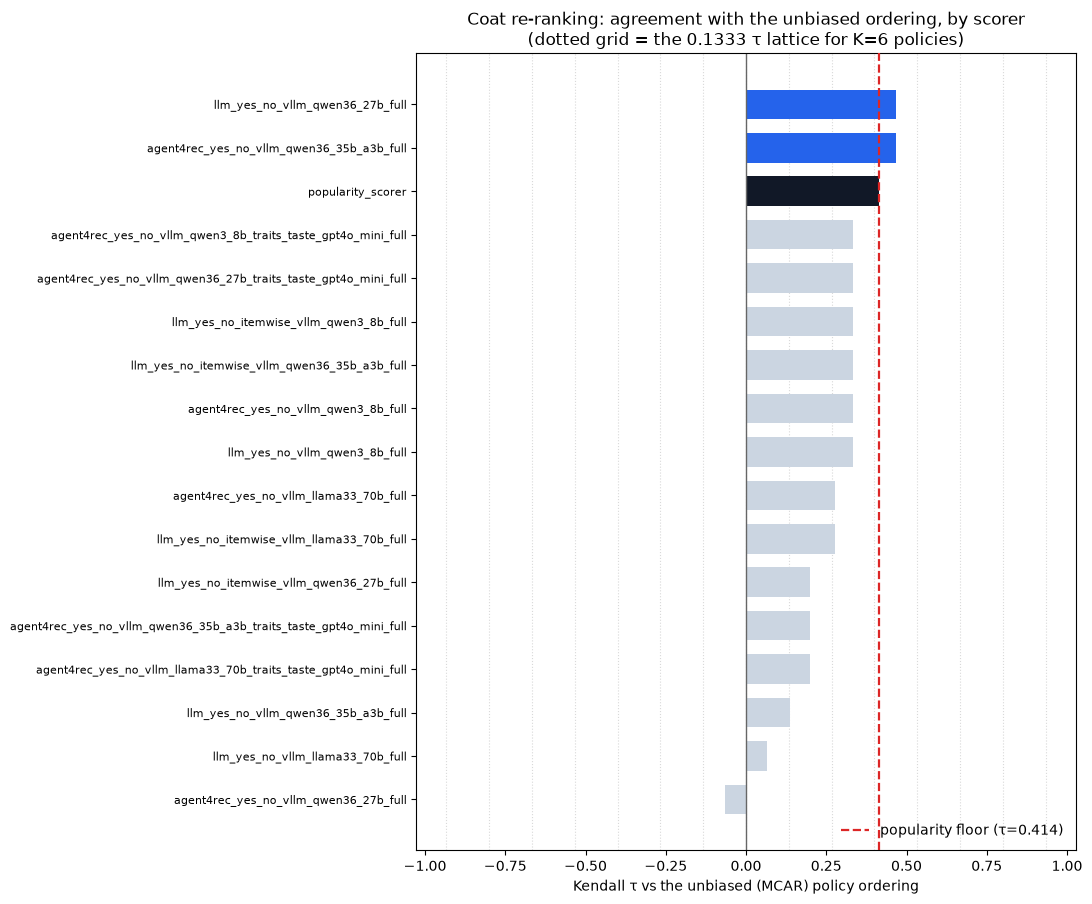

LLM scorers above the popularity floor: 2 of 16
  agent4rec_yes_no_vllm_qwen36_35b_a3b_full
  llm_yes_no_vllm_qwen36_27b_full


In [12]:
import matplotlib.pyplot as plt

if not latest_runs.empty:
    ranked = latest_runs.sort_values("kendall_tau", ascending=True).reset_index(drop=True)
    floor = latest_runs.loc[latest_runs["method"] == "popularity_scorer", "kendall_tau"]
    floor_tau = float(floor.iloc[0]) if not floor.empty else None

    colors = []
    for _, row in ranked.iterrows():
        if row["method"] == "popularity_scorer":
            colors.append("#111827")
        elif floor_tau is not None and row["kendall_tau"] > floor_tau:
            colors.append("#2563eb")
        else:
            colors.append("#cbd5e1")

    fig, ax = plt.subplots(figsize=(11, 0.42 * len(ranked) + 2))
    y = np.arange(len(ranked))
    ax.barh(y, ranked["kendall_tau"], color=colors, height=0.68)

    n_policies = int(latest_runs["n_policies"].iloc[0])
    step = 2.0 / (n_policies * (n_policies - 1) / 2)
    for k in range(-int(1 / step), int(1 / step) + 1):
        ax.axvline(k * step, color="0.85", ls=":", lw=0.8, zorder=0)
    ax.axvline(0, color="0.4", lw=1, zorder=1)
    if floor_tau is not None:
        ax.axvline(floor_tau, color="#dc2626", lw=1.6, ls="--", zorder=3,
                   label=f"popularity floor (τ={floor_tau:.3f})")

    ax.set_yticks(y)
    ax.set_yticklabels(ranked["method"], fontsize=8)
    ax.set_xlabel("Kendall τ vs the unbiased (MCAR) policy ordering")
    ax.set_title("Coat re-ranking: agreement with the unbiased ordering, by scorer\n"
                 f"(dotted grid = the {step:.4f} τ lattice for K={n_policies} policies)")
    ax.legend(loc="lower right", frameon=False)
    ax.grid(axis="x", ls=":", alpha=0.0)
    fig.tight_layout()
    plt.show()

    beat = ranked[ranked["kendall_tau"] > floor_tau]["method"].tolist() if floor_tau is not None else []
    print(f"LLM scorers above the popularity floor: {len(beat)} of {len(ranked) - 1}")
    for m in beat:
        print(f"  {m}")

## 6. How much of that is signal?

A τ leaderboard invites reading small gaps as real differences. They mostly are not. Two separate
questions, both answered by resampling the 290 users with replacement:

1. **Is the reference itself resolvable?** For each of the 15 policy pairs, how often does the bootstrap
   reproduce the sign of the real-utility difference? A pair that flips is a pair no scorer can be
   penalised or credited for ordering "wrong".
2. **How wide is a method's τ?** Recomputing τ inside each replicate propagates reference noise and
   scorer noise together, which is what an honest interval on the headline number needs.

`utility_aggregation` is `mean_score` over rows, and every (user, policy) contributes exactly k=5 rows,
so a user-level resample is an unbiased resample of the utility itself.

In [13]:
from scipy.stats import kendalltau

N_BOOT = 2000
BOOT_SEED = 0


def load_utility_matrices(run: str) -> tuple[np.ndarray, np.ndarray, list[str], list[Any]]:
    """Per-user, per-policy mean simulated score and mean real target.

    Returns (S, R, policies, users) with S/R shaped (n_users, n_policies).
    NaN scores (LLM parse failures) are skipped on the simulated side only —
    the real side always has a label, which is the point of the pool protocol.
    """
    preds = pd.read_parquet(RESULTS_ROOT / run / "predictions.parquet")
    policies = sorted(preds["policy"].unique())
    users = sorted(preds["user_id"].unique())
    sim = (preds.pivot_table(index="user_id", columns="policy", values="score", aggfunc="mean")
                .reindex(index=users, columns=policies))
    real = (preds.pivot_table(index="user_id", columns="policy", values="target", aggfunc="mean")
                 .reindex(index=users, columns=policies))
    return sim.to_numpy(float), real.to_numpy(float), policies, users


def bootstrap_run(run: str, n_boot: int = N_BOOT, seed: int = BOOT_SEED) -> dict[str, Any]:
    S, R, policies, users = load_utility_matrices(run)
    rng = np.random.default_rng(seed)
    n = len(users)
    taus = np.empty(n_boot)
    real_signs = np.zeros((len(policies), len(policies)))
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        sim_u = np.nanmean(S[idx], axis=0)
        real_u = np.nanmean(R[idx], axis=0)
        taus[b] = kendalltau(sim_u, real_u).statistic
        real_signs += np.sign(real_u[:, None] - real_u[None, :])
    return {
        "policies": policies,
        "taus": taus,
        "real_sign_mean": real_signs / n_boot,
    }

In [14]:
if not latest_runs.empty:
    # The reference is (almost) shared, so resolvability is computed once, on the
    # popularity run — the real side of every run is the same 8,700 labels.
    ref_run = latest_runs.loc[latest_runs["method"] == "popularity_scorer", "run"]
    ref_run = ref_run.iloc[0] if not ref_run.empty else latest_runs.iloc[0]["run"]
    boot_ref = bootstrap_run(ref_run)
    policies = boot_ref["policies"]
    point = latest_runs.iloc[0]["real_utilities"]

    from itertools import combinations
    pair_rows = []
    for i, j in combinations(range(len(policies)), 2):
        pi, pj = policies[i], policies[j]
        point_sign = np.sign(point[pi] - point[pj])
        # fraction of replicates reproducing the point-estimate sign
        agree = (boot_ref["real_sign_mean"][i, j] * point_sign + 1) / 2
        pair_rows.append({
            "policy_a": pi, "policy_b": pj,
            "real_gap": point[pi] - point[pj],
            "sign_agreement": agree,
            "resolvable_95": agree >= 0.95,
        })
    pairs_df = pd.DataFrame(pair_rows).sort_values("sign_agreement", ascending=False)
    n_res = int(pairs_df["resolvable_95"].sum())
    display(pairs_df.style.format({"real_gap": "{:+.4f}", "sign_agreement": "{:.3f}"})
            .hide(axis="index")
            .set_caption(f"Reference resolvability: {n_res} of {len(pairs_df)} pairs stable at 95%"))
    print(f"{n_res} of {len(pairs_df)} policy pairs have a reference ordering that survives resampling.")
    print(f"Ceiling on a meaningful τ: a scorer can only be judged on those {n_res} pairs;")
    print(f"the other {len(pairs_df) - n_res} contribute noise to every method equally.")

policy_a,policy_b,real_gap,sign_agreement,resolvable_95
ALSPolicy,ItemKNNPolicy,+0.0303,1.000,True
ALSPolicy,RandomPolicy,+0.0821,1.000,True
BPRPolicy,RandomPolicy,+0.0724,1.000,True
ItemKNNPolicy,RandomPolicy,+0.0517,1.000,True
LightGCNTorchPolicy,RandomPolicy,+0.0648,1.000,True
PopularityPolicy,RandomPolicy,+0.0697,1.000,True
BPRPolicy,ItemKNNPolicy,+0.0207,0.986,True
ALSPolicy,LightGCNTorchPolicy,+0.0172,0.978,True
ItemKNNPolicy,PopularityPolicy,-0.0179,0.958,True
ALSPolicy,BPRPolicy,+0.0097,0.925,False


9 of 15 policy pairs have a reference ordering that survives resampling.
Ceiling on a meaningful τ: a scorer can only be judged on those 9 pairs;
the other 6 contribute noise to every method equally.


In [15]:
if not latest_runs.empty:
    boot_rows = []
    for _, row in latest_runs.iterrows():
        if not row["has_predictions"]:
            continue
        res = bootstrap_run(row["run"])
        taus = res["taus"]
        boot_rows.append({
            "method": row["method"],
            "tau_point": row["kendall_tau"],
            "tau_boot_mean": float(np.nanmean(taus)),
            "ci_lo": float(np.nanpercentile(taus, 2.5)),
            "ci_hi": float(np.nanpercentile(taus, 97.5)),
            "p_tau_gt_0": float(np.nanmean(taus > 0)),
        })
    boot_df = pd.DataFrame(boot_rows).sort_values("tau_point", ascending=False)
    boot_df["ci_width"] = boot_df["ci_hi"] - boot_df["ci_lo"]
    display(boot_df.style.format({
        "tau_point": "{:.4f}", "tau_boot_mean": "{:.4f}",
        "ci_lo": "{:+.4f}", "ci_hi": "{:+.4f}", "ci_width": "{:.4f}", "p_tau_gt_0": "{:.3f}",
    }).hide(axis="index").set_caption(
        f"Kendall τ with a user-level bootstrap ({N_BOOT} replicates, 290 users resampled)"
    ))

method,tau_point,tau_boot_mean,ci_lo,ci_hi,p_tau_gt_0,ci_width
agent4rec_yes_no_vllm_qwen36_35b_a3b_full,0.4667,0.2642,-0.2000,+0.7333,0.885,0.9333
llm_yes_no_vllm_qwen36_27b_full,0.4667,0.3757,-0.0667,+0.7333,0.944,0.8000
popularity_scorer,0.4140,0.4092,+0.0667,+0.7333,0.991,0.6667
llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full,0.3333,0.3114,-0.0667,+0.6000,0.954,0.6667
llm_yes_no_vllm_qwen3_8b_full,0.3333,0.2630,-0.2000,+0.7333,0.879,0.9333
agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full,0.3333,0.3029,-0.0667,+0.6000,0.953,0.6667
agent4rec_yes_no_vllm_qwen3_8b_full,0.3333,0.2365,-0.0667,+0.6000,0.893,0.6667
agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full,0.3333,0.1956,-0.2000,+0.6000,0.841,0.8000
llm_yes_no_itemwise_vllm_qwen3_8b_full,0.3333,0.2440,-0.2000,+0.6000,0.886,0.8000
agent4rec_yes_no_vllm_llama33_70b_full,0.2760,0.3057,-0.0667,+0.7333,0.905,0.8000


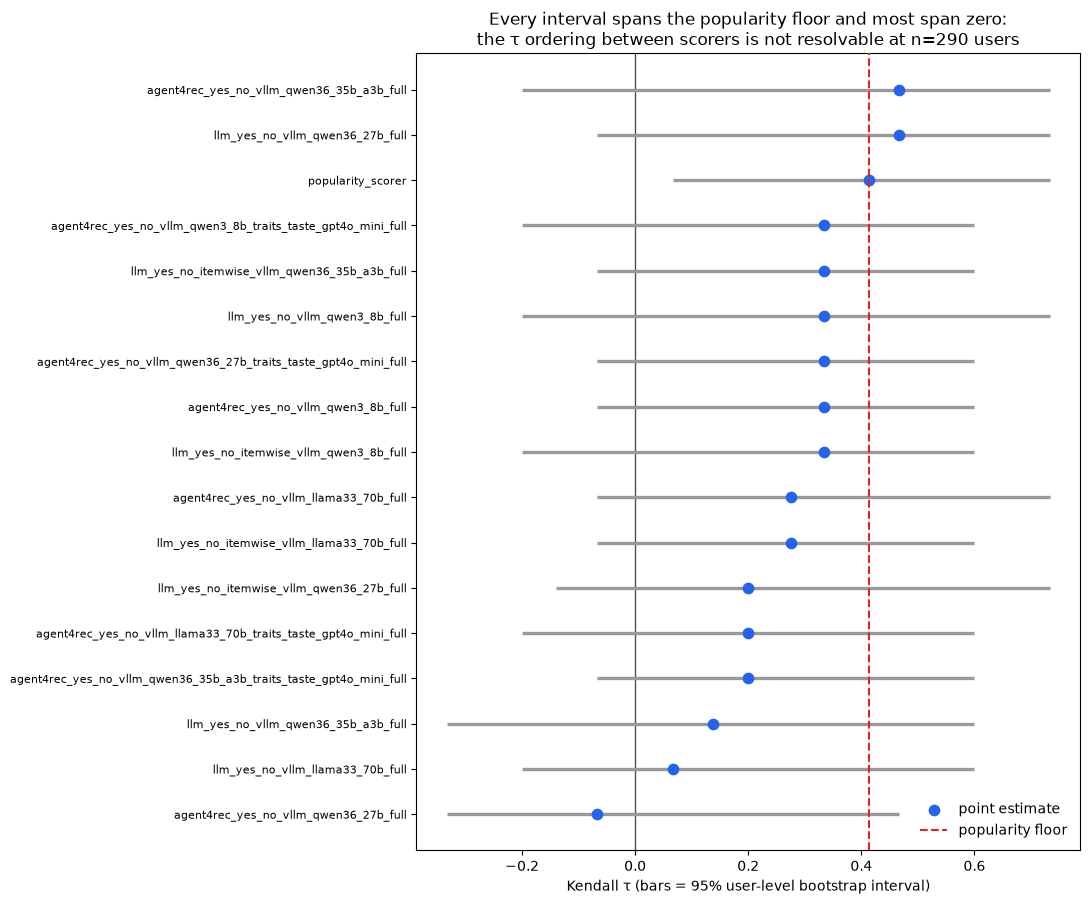

methods whose 95% interval includes τ=0: 16 of 17
methods whose 95% interval includes the popularity floor: 17 of 17


In [16]:
if not latest_runs.empty and not boot_df.empty:
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(boot_df) + 2))
    order = boot_df.sort_values("tau_point", ascending=True).reset_index(drop=True)
    y = np.arange(len(order))
    ax.hlines(y, order["ci_lo"], order["ci_hi"], color="0.6", lw=2.4, zorder=1)
    ax.scatter(order["tau_point"], y, s=55, color="#2563eb", zorder=2, label="point estimate")
    ax.axvline(0, color="0.3", lw=1, zorder=0)
    floor_row = order[order["method"] == "popularity_scorer"]
    if not floor_row.empty:
        ax.axvline(float(floor_row["tau_point"].iloc[0]), color="#dc2626", ls="--", lw=1.5,
                   label="popularity floor", zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(order["method"], fontsize=8)
    ax.set_xlabel("Kendall τ (bars = 95% user-level bootstrap interval)")
    ax.set_title("Every interval spans the popularity floor and most span zero:\n"
                 "the τ ordering between scorers is not resolvable at n=290 users")
    ax.legend(loc="lower right", frameon=False)
    fig.tight_layout()
    plt.show()

    spans_zero = int((boot_df["ci_lo"] <= 0).sum())
    print(f"methods whose 95% interval includes τ=0: {spans_zero} of {len(boot_df)}")
    floor_tau_v = float(boot_df.loc[boot_df["method"] == "popularity_scorer", "tau_point"].iloc[0])
    spans_floor = int(((boot_df["ci_lo"] <= floor_tau_v) & (boot_df["ci_hi"] >= floor_tau_v)).sum())
    print(f"methods whose 95% interval includes the popularity floor: {spans_floor} of {len(boot_df)}")

## 7. Per-policy utilities

The per-policy mean simulated score (what the scorer believes about those slates) next to the per-policy
mean real target (the unbiased hit rate). Kendall's τ is a function of nothing but the *ordering* of these
two columns — the levels are free to disagree completely.

In [17]:
def expand_utilities(runs: pd.DataFrame) -> pd.DataFrame:
    """Expand simulated_utilities / real_utilities dicts into long format."""
    rows = []
    for _, run in runs.iterrows():
        sim_util = run["simulated_utilities"]
        real_util = run["real_utilities"]
        for policy in sorted(set(sim_util) | set(real_util)):
            rows.append({
                "method": run["method"],
                "backbone": run["backbone"],
                "family": run["family"],
                "policy": policy,
                "simulated_utility": sim_util.get(policy),
                "real_utility": real_util.get(policy),
                "simulated_rank_position": (
                    run["simulated_rank"].index(policy) + 1 if policy in run["simulated_rank"] else None
                ),
                "real_rank_position": (
                    run["real_rank"].index(policy) + 1 if policy in run["real_rank"] else None
                ),
            })
    return pd.DataFrame(rows)


if not latest_runs.empty:
    utilities_df = expand_utilities(latest_runs)
    utilities_df["rank_error"] = (
        utilities_df["simulated_rank_position"] - utilities_df["real_rank_position"]
    )
    pivot = utilities_df.pivot_table(
        index="method", columns="policy", values="simulated_utility", aggfunc="first"
    )
    display(pivot.style.format("{:.4f}", na_rep="--")
            .background_gradient(cmap="Blues", axis=1)
            .set_caption("Simulated utility (mean yes-rate) per policy — shaded within each row"))

policy,ALSPolicy,BPRPolicy,ItemKNNPolicy,LightGCNTorchPolicy,PopularityPolicy,RandomPolicy
method,,,,,,
agent4rec_yes_no_vllm_llama33_70b_full,0.5255,0.5310,0.5200,0.5324,0.4186,0.4186
agent4rec_yes_no_vllm_llama33_70b_traits_taste_gpt4o_mini_full,0.4290,0.4483,0.4386,0.4510,0.3228,0.3041
agent4rec_yes_no_vllm_qwen36_27b_full,0.3759,0.3910,0.3917,0.4110,0.2903,0.3048
agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full,0.3248,0.3517,0.3262,0.3510,0.2586,0.2379
agent4rec_yes_no_vllm_qwen36_35b_a3b_full,0.3476,0.3207,0.3386,0.3421,0.2669,0.2662
agent4rec_yes_no_vllm_qwen36_35b_a3b_traits_taste_gpt4o_mini_full,0.3524,0.3910,0.3529,0.3966,0.2657,0.2517
agent4rec_yes_no_vllm_qwen3_8b_full,0.2048,0.2457,0.1924,0.2262,0.1524,0.1779
agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full,0.2814,0.3379,0.3034,0.3372,0.2241,0.2207
llm_yes_no_itemwise_vllm_llama33_70b_full,0.1469,0.1655,0.1490,0.1586,0.0924,0.0834


In [19]:
if not latest_runs.empty:
    # Simulated levels vary wildly between scorers; the ordering is what τ reads.
    spread = (
        utilities_df.groupby("method")["simulated_utility"]
        .agg(min="min", max="max", mean="mean")
        .assign(span=lambda d: d["max"] - d["min"])
        .sort_values("span", ascending=False)
    )
    display(spread.style.format("{:.4f}").set_caption(
        "Simulated-utility spread across the 6 policies. A near-zero span means the scorer "
        "says yes at nearly the same rate whatever it is shown — τ is then decided by noise."
    ))

,min,max,mean,span
method,,,,
popularity_scorer,6.1207,12.4359,8.5480,6.3152
agent4rec_yes_no_vllm_llama33_70b_traits_taste_gpt4o_mini_full,0.3041,0.4510,0.3990,0.1469
agent4rec_yes_no_vllm_qwen36_35b_a3b_traits_taste_gpt4o_mini_full,0.2517,0.3966,0.3351,0.1448
agent4rec_yes_no_vllm_qwen36_27b_full,0.2903,0.4110,0.3608,0.1207
agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full,0.2207,0.3379,0.2841,0.1172
agent4rec_yes_no_vllm_llama33_70b_full,0.4186,0.5324,0.4910,0.1138
agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full,0.2379,0.3517,0.3084,0.1138
llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full,0.1048,0.2179,0.1763,0.1131
agent4rec_yes_no_vllm_qwen3_8b_full,0.1524,0.2457,0.1999,0.0933


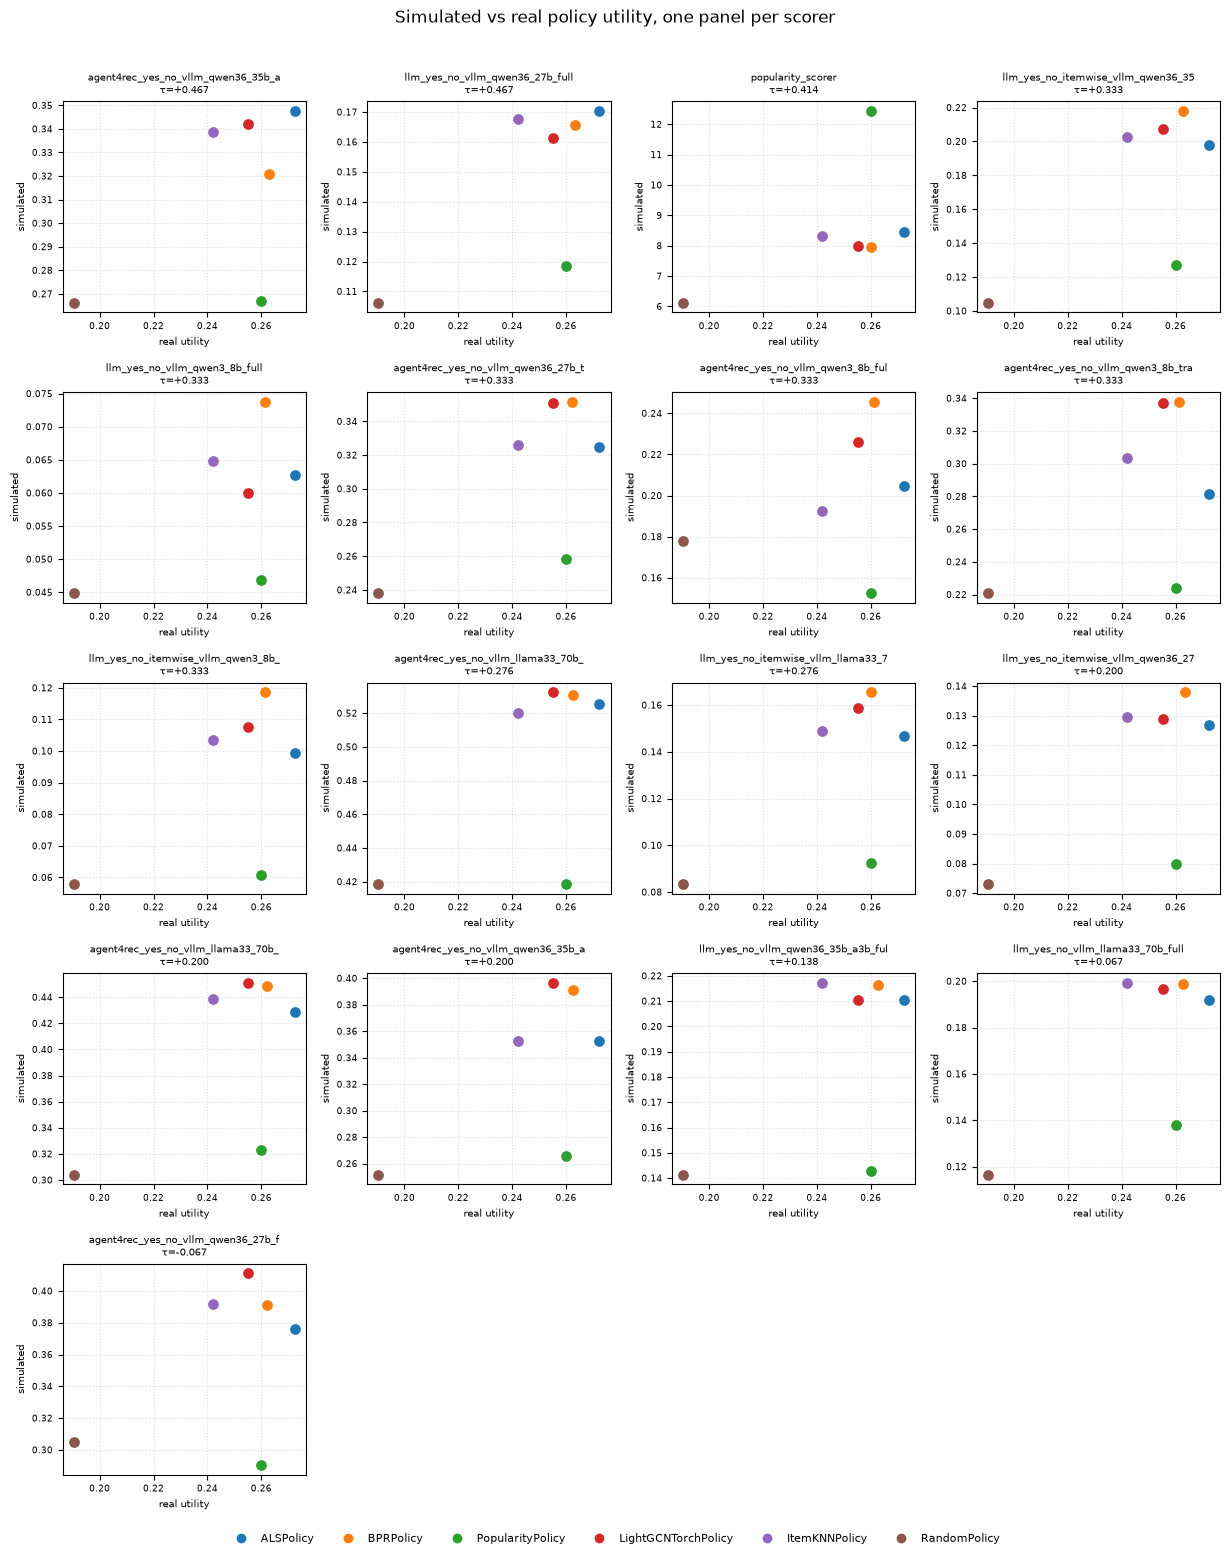

In [20]:
if not latest_runs.empty:
    methods = list(latest_runs.sort_values("kendall_tau", ascending=False)["method"])
    ncols, nrows = 4, int(np.ceil(len(methods) / 4))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.1 * ncols, 3.0 * nrows), squeeze=False)
    policies_sorted = latest_runs.iloc[0]["real_rank"]
    cmap = plt.get_cmap("tab10")
    color_by_policy = {p: cmap(i % 10) for i, p in enumerate(policies_sorted)}

    for ax, method in zip(axes.ravel(), methods):
        sub = utilities_df[utilities_df["method"] == method]
        for _, r in sub.iterrows():
            ax.scatter(r["real_utility"], r["simulated_utility"],
                       color=color_by_policy[r["policy"]], s=45, zorder=2)
        tau = float(latest_runs.loc[latest_runs["method"] == method, "kendall_tau"].iloc[0])
        ax.set_title(f"{method[:34]}\nτ={tau:+.3f}", fontsize=7.5)
        ax.set_xlabel("real utility", fontsize=7)
        ax.set_ylabel("simulated", fontsize=7)
        ax.tick_params(labelsize=6.5)
        ax.grid(ls=":", alpha=0.4)
    for ax in axes.ravel()[len(methods):]:
        ax.axis("off")

    handles = [plt.Line2D([], [], marker="o", ls="", color=color_by_policy[p], label=p)
               for p in policies_sorted]
    fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, fontsize=8,
               bbox_to_anchor=(0.5, -0.02))
    fig.suptitle("Simulated vs real policy utility, one panel per scorer", y=1.01)
    fig.tight_layout()
    plt.show()

## 8. Where the rankings diverge

Two views of the same disagreement. The bump chart shows which policies a single scorer moves; the
concordance heatmap decomposes τ by policy pair and aggregates **across the 16 LLM scorers** — the ml-1m
version aggregated across seeds, which does not exist here.

A pair that most scorers get wrong is more interesting than a low τ: it names *which* comparison the
simulators cannot make.

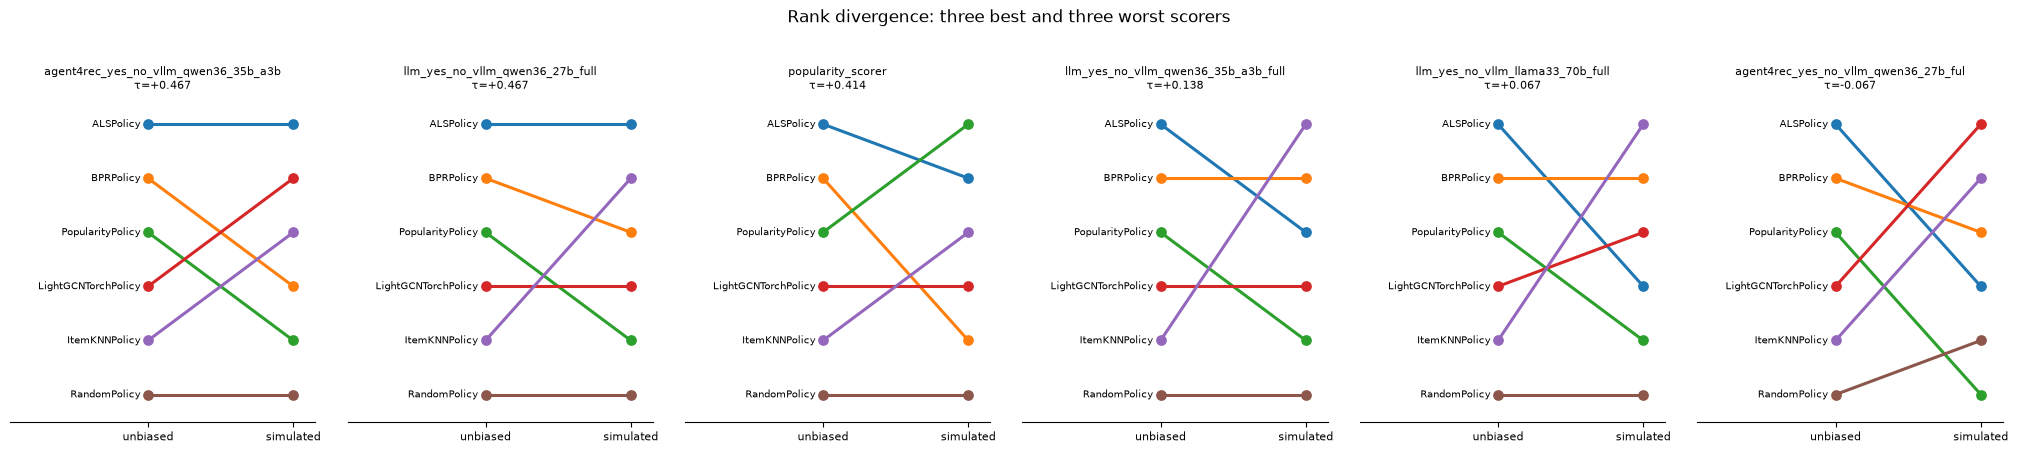

In [21]:
def plot_rank_bump(df: pd.DataFrame, method: str, ax=None):
    """Real rank vs simulated rank for one run."""
    sub = df[df["method"] == method]
    if sub.empty:
        raise ValueError(f"No run for method={method!r}")
    row = sub.iloc[0]
    real_order, sim_order = row["real_rank"], row["simulated_rank"]
    cmap = plt.get_cmap("tab10")
    colors = {p: cmap(i % 10) for i, p in enumerate(real_order)}

    created = ax is None
    if created:
        _, ax = plt.subplots(figsize=(4.6, 4.2))
    for p in real_order:
        y_real, y_sim = real_order.index(p), sim_order.index(p)
        ax.plot([0, 1], [y_real, y_sim], color=colors[p], lw=2.2, zorder=1)
        ax.scatter(0, y_real, s=45, color=colors[p], zorder=2)
        ax.scatter(1, y_sim, s=45, color=colors[p], zorder=2)
        ax.text(-0.05, y_real, p, ha="right", va="center", fontsize=7)
    ax.set_xlim(-0.95, 1.15)
    ax.set_ylim(len(real_order) - 0.5, -0.5)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["unbiased", "simulated"], fontsize=8)
    ax.set_yticks([])
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    tau = float(row["kendall_tau"])
    ax.set_title(f"{method[:36]}\nτ={tau:+.3f}", fontsize=8)
    return ax


if not latest_runs.empty:
    ordered = latest_runs.sort_values("kendall_tau", ascending=False)
    show = pd.concat([ordered.head(3), ordered.tail(3)])["method"].tolist()
    fig, axes = plt.subplots(1, len(show), figsize=(3.4 * len(show), 4.4))
    for ax, method in zip(np.atleast_1d(axes), show):
        plot_rank_bump(latest_runs, method, ax=ax)
    fig.suptitle("Rank divergence: three best and three worst scorers", y=1.02)
    fig.tight_layout()
    plt.show()

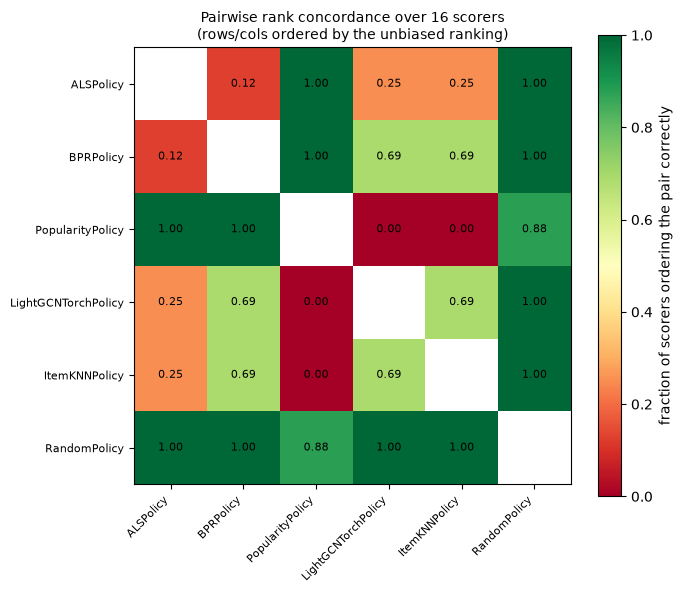

pair,scorers_correct
PopularityPolicy > LightGCNTorchPolicy,0.00
PopularityPolicy > ItemKNNPolicy,0.00
ALSPolicy > BPRPolicy,0.12
ALSPolicy > LightGCNTorchPolicy,0.25
ALSPolicy > ItemKNNPolicy,0.25


In [22]:
from itertools import combinations


def plot_pairwise_concordance(df: pd.DataFrame, figsize=(7, 6)):
    """Fraction of scorers that order each policy pair the way the unbiased data does."""
    real_order = df.iloc[0]["real_rank"]
    n = len(real_order)
    mat = np.full((n, n), np.nan)
    for i, j in combinations(range(n), 2):
        pi, pj = real_order[i], real_order[j]
        agree = []
        for _, row in df.iterrows():
            real_sign = np.sign(row["real_rank"].index(pi) - row["real_rank"].index(pj))
            sim_sign = np.sign(row["simulated_rank"].index(pi) - row["simulated_rank"].index(pj))
            agree.append(real_sign == sim_sign)
        mat[i, j] = mat[j, i] = float(np.mean(agree))

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(mat, cmap="RdYlGn", vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(real_order, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(n)); ax.set_yticklabels(real_order, fontsize=8)
    for i in range(n):
        for j in range(n):
            if i != j:
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=ax, label="fraction of scorers ordering the pair correctly")
    ax.set_title(f"Pairwise rank concordance over {len(df)} scorers\n"
                 "(rows/cols ordered by the unbiased ranking)", fontsize=10)
    fig.tight_layout()
    return fig, mat


if not latest_runs.empty:
    llm_runs = latest_runs[latest_runs["family"] != "non-llm"]
    fig, conc = plot_pairwise_concordance(llm_runs)
    plt.show()

    real_order = llm_runs.iloc[0]["real_rank"]
    flat = [
        {"pair": f"{real_order[i]} > {real_order[j]}", "scorers_correct": conc[i, j]}
        for i, j in combinations(range(len(real_order)), 2)
    ]
    flat_df = pd.DataFrame(flat).sort_values("scorers_correct")
    display(flat_df.head(5).style.format({"scorers_correct": "{:.2f}"}).hide(axis="index")
            .set_caption("Hardest pairs — comparisons the LLM scorers most often invert"))

## 9. Scorer-family cuts

Three design questions the roster was built to answer, each isolating one factor while holding the
backbone fixed. Read the deltas against the bootstrap intervals from section 6 before concluding anything.

In [23]:
if not latest_runs.empty:
    llm = latest_runs[latest_runs["family"] != "non-llm"]

    def cut(index: str, columns: str, caption: str) -> None:
        table = llm.pivot_table(index=index, columns=columns, values="kendall_tau", aggfunc="mean")
        display(table.style.format("{:.4f}", na_rep="--")
                .background_gradient(cmap="RdYlGn", vmin=-1, vmax=1)
                .set_caption(caption))

    cut("backbone", "family", "Backbone × scorer family (mean τ)")
    cut("backbone", "prompt_style", "Backbone × prompt style — batch slate vs one call per item")
    cut("backbone", "persona", "Agent4Rec only: traits vs traits+taste (gpt-4o-mini)")

family,agent4rec,history
backbone,,
llama33_70b,0.2380,0.1713
qwen36_27b,0.1333,0.3333
qwen36_35b_a3b,0.3333,0.2357
qwen3_8b,0.3333,0.3333


prompt_style,batch,itemwise
backbone,,
llama33_70b,0.1809,0.2760
qwen36_27b,0.2444,0.2000
qwen36_35b_a3b,0.2682,0.3333
qwen3_8b,0.3333,0.3333


persona,--,traits,traits+taste
backbone,,,
llama33_70b,0.1713,0.2760,0.2000
qwen36_27b,0.3333,-0.0667,0.3333
qwen36_35b_a3b,0.2357,0.4667,0.2000
qwen3_8b,0.3333,0.3333,0.3333


In [25]:
if not latest_runs.empty:
    # Paired deltas: same backbone, one factor flipped.
    def paired_delta(mask_a, mask_b, label_a: str, label_b: str, key: str = "backbone") -> pd.DataFrame:
        a = latest_runs[mask_a].set_index(key)["kendall_tau"]
        b = latest_runs[mask_b].set_index(key)["kendall_tau"]
        shared = sorted(set(a.index) & set(b.index))
        return pd.DataFrame({
            key: shared,
            label_a: [a[i] for i in shared],
            label_b: [b[i] for i in shared],
            "delta": [b[i] - a[i] for i in shared],
        })

    hist = latest_runs["family"] == "history"
    a4r = latest_runs["family"] == "agent4rec"
    batch = latest_runs["prompt_style"] == "batch"
    item = latest_runs["prompt_style"] == "itemwise"
    traits = latest_runs["persona"] == "traits"
    taste = latest_runs["persona"] == "traits+taste"

    for title, frame in [
        ("history: batch → itemwise", paired_delta(hist & batch, hist & item, "batch", "itemwise")),
        ("agent4rec: traits → traits+taste", paired_delta(a4r & traits, a4r & taste, "traits", "traits+taste")),
        ("batch: history → agent4rec", paired_delta(hist & batch, a4r & batch & traits, "history", "agent4rec")),
    ]:
        print(f"\n=== {title} ===")
        if frame.empty:
            print("  (no paired runs)")
            continue
        print(frame.to_string(index=False, float_format=lambda v: f"{v:+.4f}"))
        print(f"  mean delta: {frame['delta'].mean():+.4f}")


=== history: batch → itemwise ===
      backbone   batch  itemwise   delta
   llama33_70b +0.0667   +0.2760 +0.2094
    qwen36_27b +0.4667   +0.2000 -0.2667
qwen36_35b_a3b +0.1380   +0.3333 +0.1953
      qwen3_8b +0.3333   +0.3333 +0.0000
  mean delta: +0.0345

=== agent4rec: traits → traits+taste ===
      backbone  traits  traits+taste   delta
   llama33_70b +0.2760       +0.2000 -0.0760
    qwen36_27b -0.0667       +0.3333 +0.4000
qwen36_35b_a3b +0.4667       +0.2000 -0.2667
      qwen3_8b +0.3333       +0.3333 +0.0000
  mean delta: +0.0143

=== batch: history → agent4rec ===
      backbone  history  agent4rec   delta
   llama33_70b  +0.0667    +0.2760 +0.2094
    qwen36_27b  +0.4667    -0.0667 -0.5333
qwen36_35b_a3b  +0.1380    +0.4667 +0.3287
      qwen3_8b  +0.3333    +0.3333 +0.0000
  mean delta: +0.0012


## 10. Call volume and dedup

`requested` is the number of scoring groups the protocol produces; `unique_score_units` is how many
actually reached the LLM after deduplication. The history family collapses identical questions
(`user::item` for itemwise, the slate signature for batch); the Agent4Rec path does not report a
dedup count, so its `requested` is what it spent.

In [26]:
if not latest_runs.empty:
    cost = latest_runs[[
        "method", "family", "prompt_style", "requested_groups", "unique_score_units",
        "requested_rows", "scored_rows", "llm_errors",
    ]].copy()
    cost["dedup_factor"] = cost["requested_groups"] / cost["unique_score_units"]
    cost["unscored_rows"] = cost["requested_rows"] - cost["scored_rows"]
    display(cost.sort_values(["family", "prompt_style", "method"]).style.format({
        "dedup_factor": "{:.2f}×",
    }, na_rep="--").hide(axis="index").set_caption("LLM call accounting per run"))

    total = cost["unique_score_units"].fillna(cost["requested_groups"]).sum()
    print(f"Total LLM calls across the sweep (dedup applied where reported): {int(total):,}")

method,family,prompt_style,requested_groups,unique_score_units,requested_rows,scored_rows,llm_errors,dedup_factor,unscored_rows
agent4rec_yes_no_vllm_llama33_70b_full,agent4rec,batch,1740.000000,--,8700.000000,8700.000000,0.000000,--,0.000000
agent4rec_yes_no_vllm_llama33_70b_traits_taste_gpt4o_mini_full,agent4rec,batch,1740.000000,--,8700.000000,8700.000000,0.000000,--,0.000000
agent4rec_yes_no_vllm_qwen36_27b_full,agent4rec,batch,1740.000000,--,8700.000000,8700.000000,0.000000,--,0.000000
agent4rec_yes_no_vllm_qwen36_27b_traits_taste_gpt4o_mini_full,agent4rec,batch,1740.000000,--,8700.000000,8700.000000,0.000000,--,0.000000
agent4rec_yes_no_vllm_qwen36_35b_a3b_full,agent4rec,batch,1740.000000,--,8700.000000,8700.000000,0.000000,--,0.000000
agent4rec_yes_no_vllm_qwen36_35b_a3b_traits_taste_gpt4o_mini_full,agent4rec,batch,1740.000000,--,8700.000000,8690.000000,2.000000,--,10.000000
agent4rec_yes_no_vllm_qwen3_8b_full,agent4rec,batch,1740.000000,--,8700.000000,8695.000000,1.000000,--,5.000000
agent4rec_yes_no_vllm_qwen3_8b_traits_taste_gpt4o_mini_full,agent4rec,batch,1740.000000,--,8700.000000,8700.000000,0.000000,--,0.000000
llm_yes_no_vllm_llama33_70b_full,history,batch,1740.000000,1709.000000,8700.000000,8700.000000,0.000000,1.02×,0.000000
llm_yes_no_vllm_qwen36_27b_full,history,batch,1740.000000,1710.000000,8700.000000,8700.000000,0.000000,1.02×,0.000000


Total LLM calls across the sweep (dedup applied where reported): 34,442


## 11. Verifications

Structural checks on the collected artifacts. The first six carry over from the ml-1m notebook; the rest
are specific to the re-ranking protocol and would each catch a defect that produces plausible-looking
numbers rather than an error.

In [27]:
def check_policy_name_consistency(runs: pd.DataFrame) -> None:
    """Policy names in metrics must match those declared in the manifest."""
    failures = []
    for _, run in runs.iterrows():
        manifest_names = set(run["policy_names_manifest"])
        metrics_names = set(run["simulated_utilities"])
        if manifest_names and metrics_names and manifest_names != metrics_names:
            failures.append((run["run"], sorted(manifest_names), sorted(metrics_names)))
    if failures:
        print("FAIL: policy name mismatch between manifest and metrics:")
        for run, man, met in failures:
            print(f"  run={run}\n    manifest: {man}\n    metrics:  {met}")
    else:
        print(f"OK: all {len(runs)} runs have consistent policy names in manifest and metrics.")


def check_rank_order_consistent_with_utilities(runs: pd.DataFrame) -> None:
    """simulated_rank / real_rank must be the descending sort of their utilities."""
    failures = []
    for _, run in runs.iterrows():
        for kind, util, rank in (
            ("simulated", run["simulated_utilities"], run["simulated_rank"]),
            ("real", run["real_utilities"], run["real_rank"]),
        ):
            if not util:
                continue
            expected = sorted(util, key=util.__getitem__, reverse=True)
            if rank != expected:
                failures.append((run["run"], kind, rank, expected))
    if failures:
        print("FAIL: rank order inconsistent with utilities:")
        for run, kind, got, exp in failures:
            print(f"  run={run} kind={kind}\n    got:      {got}\n    expected: {exp}")
    else:
        print(f"OK: all rank orders match their utility values in {len(runs)} runs.")


def check_utility_completeness(runs: pd.DataFrame) -> None:
    """simulated_utilities and real_utilities must cover the same policies."""
    failures = []
    for _, run in runs.iterrows():
        sim, real = set(run["simulated_utilities"]), set(run["real_utilities"])
        if sim != real:
            failures.append((run["run"], sorted(sim - real), sorted(real - sim)))
    if failures:
        print("FAIL: mismatched policy names between simulated and real utilities:")
        for run, sim_only, real_only in failures:
            print(f"  run={run} sim_only={sim_only} real_only={real_only}")
    else:
        print(f"OK: simulated and real utilities cover the same policies in {len(runs)} runs.")


def check_no_duplicate_runs(runs: pd.DataFrame) -> None:
    """At most one run per (dataset, target, method, seed) after dedup."""
    dupes = (runs.groupby(["dataset", "target", "method", "seed"], dropna=False)
                 .size().rename("count").reset_index())
    dupes = dupes[dupes["count"] > 1]
    if not dupes.empty:
        print("FAIL: duplicate (dataset, target, method, seed) after deduplication:")
        display(dupes)
    else:
        print(f"OK: no duplicate (dataset, target, method, seed) entries ({len(runs)} runs).")


def check_k2_warning_present(runs: pd.DataFrame) -> None:
    """When K=2, tau/rho must be None and a warning set."""
    failures = []
    for _, run in runs.iterrows():
        if run["n_policies"] == 2:
            if run["kendall_tau"] is not None:
                failures.append((run["run"], "kendall_tau is not None for K=2"))
            if not run["warning"]:
                failures.append((run["run"], "warning is empty for K=2"))
    if failures:
        print("FAIL: K=2 invariant violated:")
        for run, issue in failures:
            print(f"  run={run}: {issue}")
    else:
        k2 = int((runs["n_policies"] == 2).sum())
        print(f"INFO: no K=2 runs (all have K={sorted(runs['n_policies'].unique())}, τ/ρ defined)."
              if not k2 else f"PASS: {k2} K=2 run(s) correctly report τ=None.")


if not latest_runs.empty:
    check_policy_name_consistency(latest_runs)
    check_rank_order_consistent_with_utilities(latest_runs)
    check_utility_completeness(latest_runs)
    check_no_duplicate_runs(latest_runs)
    check_k2_warning_present(latest_runs)

OK: all 17 runs have consistent policy names in manifest and metrics.
OK: all rank orders match their utility values in 17 runs.
OK: simulated and real utilities cover the same policies in 17 runs.
OK: no duplicate (dataset, target, method, seed) entries (17 runs).
INFO: no K=2 runs (all have K=[np.int64(6)], τ/ρ defined).


In [28]:
def check_protocol_fields(runs: pd.DataFrame, results_root: Path) -> None:
    """manifest.protocol is the method protocol; task.manifest.protocol is the task's.

    These differ on purpose: the method still runs `policy_ranking`, but the task
    was built by `PolicyRerankingTaskBuilder` and must say so. A run whose task
    protocol is `policy_ranking` would be a free-retrieval task sneaking into
    this notebook, which changes what τ means.
    """
    failures = []
    for _, run in runs.iterrows():
        manifest_path = results_root / run["run"] / "manifest.json"
        if not manifest_path.exists():
            failures.append((run["run"], "manifest.json missing"))
            continue
        protocol = read_json(manifest_path).get("protocol")
        if protocol != "policy_ranking":
            failures.append((run["run"], f"manifest.protocol={protocol!r} (expected 'policy_ranking')"))
        if run["task_manifest_protocol"] != "policy_reranking":
            failures.append((
                run["run"],
                f"task.manifest.protocol={run['task_manifest_protocol']!r} (expected 'policy_reranking')",
            ))
    if failures:
        print("FAIL:")
        for run, issue in failures:
            print(f"  run={run}: {issue}")
    else:
        print(f"OK: all {len(runs)} runs are policy_ranking methods over policy_reranking tasks.")


def check_rerank_construction(runs: pd.DataFrame) -> None:
    """Pool protocol invariants: k=5 slates drawn from a 16-item MCAR pool."""
    failures = []
    for _, run in runs.iterrows():
        if run["candidate_kind"] != "held_out_pool_rerank":
            failures.append((run["run"], f"candidate_kind={run['candidate_kind']!r}"))
        if run["candidate_k"] != 5:
            failures.append((run["run"], f"k={run['candidate_k']} (expected 5)"))
        if sorted(run["pool_sizes"]) != [16]:
            failures.append((run["run"], f"pool_sizes={run['pool_sizes']} (expected [16])"))
        if run["splitter_class"] != "SourcePartitionSplitter":
            failures.append((run["run"], f"splitter={run['splitter_class']!r}"))
        if run["dropped_overlap_rows"] != 366:
            failures.append((run["run"], f"dropped_overlap_rows={run['dropped_overlap_rows']} (expected 366)"))
    if failures:
        print("FAIL: re-ranking construction invariants:")
        for run, issue in failures:
            print(f"  run={run}: {issue}")
    else:
        print(f"OK: all {len(runs)} runs re-rank a 16-item MCAR pool to k=5, "
              f"with the 366 overlap rows removed from train.")


def check_full_slate_labelling(runs: pd.DataFrame, results_root: Path) -> None:
    """Every slate slot must carry a real label — the pool protocol forbids zero-fill.

    On a free-retrieval task an unseen (user, item) is scored 0 by construction,
    which silently biases every policy's real utility toward 0. Here the label
    join is total, so a NaN or a row count other than users x policies x k is a defect.
    """
    failures = []
    for _, run in runs.iterrows():
        preds = pd.read_parquet(results_root / run["run"] / "predictions.parquet")
        n_users = preds["user_id"].nunique()
        n_policies = preds["policy"].nunique()
        expected_rows = n_users * n_policies * int(run["candidate_k"])
        if len(preds) != expected_rows:
            failures.append((run["run"], f"{len(preds)} rows, expected {expected_rows}"))
        if preds["target"].isna().any():
            failures.append((run["run"], f"{int(preds['target'].isna().sum())} NaN targets"))
        sizes = preds.groupby(["user_id", "policy"]).size().unique()
        if list(sizes) != [int(run["candidate_k"])]:
            failures.append((run["run"], f"slate sizes {sorted(sizes)} != [{run['candidate_k']}]"))
    if failures:
        print("FAIL: slate labelling:")
        for run, issue in failures:
            print(f"  run={run}: {issue}")
    else:
        print(f"OK: all {len(runs)} runs have a fully labelled slate for every (user, policy).")


def check_coverage_floor(runs: pd.DataFrame) -> None:
    """Per-policy score coverage must clear the runner's floor in every run."""
    failures = []
    for _, run in runs.iterrows():
        per_policy = run["policy_coverage_per_policy"] or {}
        floor = run["policy_coverage_min"] or 0.90
        for policy, counts in per_policy.items():
            if counts.get("coverage", 0.0) < floor:
                failures.append((run["run"], f"{policy} coverage={counts['coverage']:.3f} < {floor}"))
        if run["policy_coverage_common_users"] != 290:
            failures.append((run["run"], f"common_users={run['policy_coverage_common_users']} (expected 290)"))
    if failures:
        print("FAIL: coverage:")
        for run, issue in failures:
            print(f"  run={run}: {issue}")
    else:
        worst = min(
            c["coverage"]
            for _, r in runs.iterrows()
            for c in (r["policy_coverage_per_policy"] or {}).values()
        )
        print(f"OK: all {len(runs)} runs keep every policy above the floor "
              f"(worst per-policy coverage: {worst:.4f}) over all 290 users.")


if not latest_runs.empty:
    check_protocol_fields(latest_runs, RESULTS_ROOT)
    check_rerank_construction(latest_runs)
    check_full_slate_labelling(latest_runs, RESULTS_ROOT)
    check_coverage_floor(latest_runs)

OK: all 17 runs are policy_ranking methods over policy_reranking tasks.
OK: all 17 runs re-rank a 16-item MCAR pool to k=5, with the 366 overlap rows removed from train.
OK: all 17 runs have a fully labelled slate for every (user, policy).
OK: all 17 runs keep every policy above the floor (worst per-policy coverage: 0.9966) over all 290 users.


In [29]:
def check_policy_config_identical(runs: pd.DataFrame, results_root: Path) -> None:
    """All runs must have been built from one policy configuration.

    If this passes while section 3 reported drifting real utilities, the drift is
    fit non-determinism (threaded `implicit` solvers), not a config difference.
    """
    import hashlib
    signatures: dict[str, list[str]] = {}
    for _, run in runs.iterrows():
        manifest = read_json(results_root / run["run"] / "manifest.json")
        policies = as_dict(as_dict(manifest.get("task")).get("manifest")).get("policies", [])
        stripped = [
            {k: v for k, v in p.items() if k not in ("rank_candidates_fallback_users",)}
            for p in policies
        ]
        digest = hashlib.sha256(json.dumps(stripped, sort_keys=True).encode()).hexdigest()[:12]
        signatures.setdefault(digest, []).append(run["method"])
    if len(signatures) == 1:
        print(f"OK: all {len(runs)} runs share one policy configuration "
              f"(sha256[:12]={next(iter(signatures))}).")
    else:
        print(f"FAIL: {len(signatures)} distinct policy configurations:")
        for digest, methods in signatures.items():
            print(f"  {digest}: {len(methods)} run(s) — {methods[:3]}")


def check_fallback_users(runs: pd.DataFrame) -> None:
    """`rank_candidates` must return a full permutation; fallbacks are reported, not silent.

    RandomPolicy falls back for all 290 users by design (it has no scores). Any
    other policy falling back for many users means its slates are seeded shuffles
    rather than model output, which quietly turns it into a second random arm.
    """
    table = pd.DataFrame([
        {"method": run["method"], **(run["policy_fallback_users"] or {})}
        for _, run in runs.iterrows()
    ]).set_index("method")
    summary = pd.DataFrame({
        "min": table.min(), "max": table.max(),
        "fraction_of_users": table.max() / 290,
    }).sort_values("max", ascending=False)
    display(summary.style.format({"fraction_of_users": "{:.1%}"})
            .set_caption("rank_candidates fallback users per policy (of 290)"))
    non_random = summary.drop(index="RandomPolicy", errors="ignore")
    worst = non_random["max"].max()
    print(f"RandomPolicy falls back for all 290 users by design (no scores to rank by).")
    print(f"Worst non-random fallback: {int(worst)} users "
          f"({worst / 290:.1%}) — those slates are seeded shuffles, not model output.")


if not latest_runs.empty:
    check_policy_config_identical(latest_runs, RESULTS_ROOT)
    check_fallback_users(latest_runs)

OK: all 17 runs share one policy configuration (sha256[:12]=07d5613dbea2).


,min,max,fraction_of_users
RandomPolicy,290,290,100.0%
ItemKNNPolicy,6,6,2.1%
ALSPolicy,3,3,1.0%
BPRPolicy,3,3,1.0%
LightGCNTorchPolicy,3,3,1.0%
PopularityPolicy,0,0,0.0%


RandomPolicy falls back for all 290 users by design (no scores to rank by).
Worst non-random fallback: 6 users (2.1%) — those slates are seeded shuffles, not model output.


## 12. Coverage matrix

Which of the 17 parity methods completed. Gaps are missing experiments, not zeros.

In [30]:
if not latest_runs.empty:
    rows = []
    for method in EXPECTED_METHODS:
        match = latest_runs[latest_runs["method"] == method]
        if match.empty:
            rows.append({"method": method, "status": "MISSING", "kendall_tau": None, "run": ""})
        else:
            run = match.iloc[0]
            rows.append({
                "method": method,
                "status": "OK",
                "kendall_tau": run["kendall_tau"],
                "run": run["run"],
            })
    coverage_df = pd.DataFrame(rows)
    missing = int((coverage_df["status"] == "MISSING").sum())
    if missing:
        print(f"WARNING: {missing} of {len(EXPECTED_METHODS)} parity method(s) missing.")
    else:
        print(f"All {len(EXPECTED_METHODS)} parity methods completed for seed 0.")
    display(
        coverage_df.style
        .apply(lambda col: ["color: red; font-weight: bold" if v == "MISSING" else "" for v in col],
               subset=["status"])
        .format({"kendall_tau": "{:.4f}"}, na_rep="--")
        .hide(axis="index")
    )

All 17 parity methods completed for seed 0.


method,status,kendall_tau,run
popularity_scorer,OK,0.4140,20260820T190855Z_coat_policy_ranking_preference_rerank_seed0_popularity_scorer
llm_yes_no_vllm_llama33_70b_full,OK,0.0667,20260820T191040Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_vllm_llama33_70b_full
llm_yes_no_vllm_qwen36_27b_full,OK,0.4667,20260820T191104Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_vllm_qwen36_27b_full
llm_yes_no_vllm_qwen36_35b_a3b_full,OK,0.1380,20260820T191103Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_vllm_qwen36_35b_a3b_full
llm_yes_no_vllm_qwen3_8b_full,OK,0.3333,20260820T191017Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_vllm_qwen3_8b_full
llm_yes_no_itemwise_vllm_llama33_70b_full,OK,0.2760,20260820T191046Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_itemwise_vllm_llama33_70b_full
llm_yes_no_itemwise_vllm_qwen36_27b_full,OK,0.2000,20260820T191438Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_itemwise_vllm_qwen36_27b_full
llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full,OK,0.3333,20260820T191140Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_itemwise_vllm_qwen36_35b_a3b_full
llm_yes_no_itemwise_vllm_qwen3_8b_full,OK,0.3333,20260820T191043Z_coat_policy_ranking_preference_rerank_seed0_llm_yes_no_itemwise_vllm_qwen3_8b_full
agent4rec_yes_no_vllm_llama33_70b_full,OK,0.2760,20260820T191016Z_coat_policy_ranking_preference_rerank_seed0_agent4rec_yes_no_vllm_llama33_70b_full


In [31]:
# Save the collected frame for downstream analysis.
# latest_runs.to_parquet("latest_runs_rerank.parquet")